In [2]:
import os

dataset_path = r"C:\Users\arjun\Downloads\NEU-CLS"

print("Dataset folder exists:", os.path.exists(dataset_path))

print("\nFiles and folders inside NEU-CLS:")
print(os.listdir(dataset_path))

Dataset folder exists: True

Files and folders inside NEU-CLS:
['train', 'valid']


In [3]:
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        if level == 2:
            continue
        for file in files[:5]:
            print("  " * (level + 1) + file)

NEU-CLS/
  train/
    train/
  valid/
    valid/


In [4]:
import os

dataset_path = r"C:\Users\arjun\Downloads\NEU-CLS"

for folder in [
    os.path.join(dataset_path, "train", "train"),
    os.path.join(dataset_path, "valid", "valid")
]:
    print("\nFolder:", folder)

    if os.path.exists(folder):
        for item in os.listdir(folder):
            item_path = os.path.join(folder, item)

            if os.path.isdir(item_path):
                print(f"{item}: {len(os.listdir(item_path))} files")
            else:
                print(item)
    else:
        print("Folder not found")


Folder: C:\Users\arjun\Downloads\NEU-CLS\train\train
images: 0 files
labels: 1770 files
labels.cache

Folder: C:\Users\arjun\Downloads\NEU-CLS\valid\valid
images: 30 files
labels: 30 files
labels.cache


In [5]:
import os

dataset_path = r"C:\Users\arjun\Downloads\NEU-CLS"

for split in ["train", "valid"]:
    images_path = os.path.join(dataset_path, split, split, "images")
    labels_path = os.path.join(dataset_path, split, split, "labels")

    print(f"\n--- {split.upper()} ---")

    for folder in [images_path, labels_path]:
        print("\nFolder:", folder)
        print("Exists:", os.path.exists(folder))

        if os.path.exists(folder):
            files = os.listdir(folder)
            print("Number of items:", len(files))
            print("First 10 items:", files[:10])


--- TRAIN ---

Folder: C:\Users\arjun\Downloads\NEU-CLS\train\train\images
Exists: True
Number of items: 0
First 10 items: []

Folder: C:\Users\arjun\Downloads\NEU-CLS\train\train\labels
Exists: True
Number of items: 1770
First 10 items: ['crazing_10.txt', 'crazing_100.txt', 'crazing_101.txt', 'crazing_102.txt', 'crazing_103.txt', 'crazing_104.txt', 'crazing_105.txt', 'crazing_106.txt', 'crazing_107.txt', 'crazing_108.txt']

--- VALID ---

Folder: C:\Users\arjun\Downloads\NEU-CLS\valid\valid\images
Exists: True
Number of items: 30
First 10 items: ['crazing_1.jpg', 'crazing_2.jpg', 'crazing_3.jpg', 'crazing_4.jpg', 'crazing_5.jpg', 'inclusion_1.jpg', 'inclusion_2.jpg', 'inclusion_3.jpg', 'inclusion_4.jpg', 'inclusion_5.jpg']

Folder: C:\Users\arjun\Downloads\NEU-CLS\valid\valid\labels
Exists: True
Number of items: 30
First 10 items: ['crazing_1.txt', 'crazing_2.txt', 'crazing_3.txt', 'crazing_4.txt', 'crazing_5.txt', 'inclusion_1.txt', 'inclusion_2.txt', 'inclusion_3.txt', 'inclusion_4

In [6]:
import zipfile
import os

zip_path = r"C:\Users\arjun\Downloads\NEU-CLS.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    print("Total files in ZIP:", len(files))

    # Show image files
    image_files = [
        f for f in files
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print("Total images in ZIP:", len(image_files))
    print("\nFirst 20 image paths:")

    for f in image_files[:20]:
        print(f)

Total files in ZIP: 3610
Total images in ZIP: 1800

First 20 image paths:
train/train/images/crazing_10.jpg
train/train/images/crazing_100.jpg
train/train/images/crazing_101.jpg
train/train/images/crazing_102.jpg
train/train/images/crazing_103.jpg
train/train/images/crazing_104.jpg
train/train/images/crazing_105.jpg
train/train/images/crazing_106.jpg
train/train/images/crazing_107.jpg
train/train/images/crazing_108.jpg
train/train/images/crazing_109.jpg
train/train/images/crazing_11.jpg
train/train/images/crazing_110.jpg
train/train/images/crazing_111.jpg
train/train/images/crazing_112.jpg
train/train/images/crazing_113.jpg
train/train/images/crazing_114.jpg
train/train/images/crazing_115.jpg
train/train/images/crazing_116.jpg
train/train/images/crazing_117.jpg


In [7]:
import zipfile
import os

zip_path = r"C:\Users\arjun\Downloads\NEU-CLS.zip"

extract_path = r"C:\Users\arjun\Downloads\NEU-CLS_fixed"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: C:\Users\arjun\Downloads\NEU-CLS_fixed


In [8]:
import os

dataset_path = r"C:\Users\arjun\Downloads\NEU-CLS_fixed"

for split in ["train", "valid"]:
    image_path = os.path.join(
        dataset_path, split, split, "images"
    )

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{split} images:", len(images))

train images: 1770
valid images: 30


In [9]:
import os
from collections import Counter

dataset_path = r"C:\Users\arjun\Downloads\NEU-CLS_fixed"

for split in ["train", "valid"]:
    image_path = os.path.join(
        dataset_path, split, split, "images"
    )

    image_files = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts = Counter(
        f.rsplit("_", 1)[0] for f in image_files
    )

    print(f"\n{split.upper()} CLASS COUNTS")
    for class_name, count in sorted(class_counts.items()):
        print(f"{class_name}: {count}")

    print("Total:", len(image_files))


TRAIN CLASS COUNTS
crazing: 295
inclusion: 295
patches: 295
pitted_surface: 295
rolled-in_scale: 295
scratches: 295
Total: 1770

VALID CLASS COUNTS
crazing: 5
inclusion: 5
patches: 5
pitted_surface: 5
rolled-in_scale: 5
scratches: 5
Total: 30


In [11]:
import os
import shutil
from sklearn.model_selection import train_test_split

source_path = r"C:\Users\arjun\Downloads\NEU-CLS_fixed"

output_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset"

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

# Collect the original images from both folders
image_records = []

for split in ["train", "valid"]:
    folder = os.path.join(source_path, split, split, "images")

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            class_name = filename.rsplit("_", 1)[0]

            if class_name in classes:
                image_records.append(
                    (os.path.join(folder, filename), class_name)
                )

print("Total original images:", len(image_records))

# Split into 70% training and 30% temporary data
train_records, temp_records = train_test_split(
    image_records,
    test_size=0.30,
    random_state=42,
    stratify=[record[1] for record in image_records]
)

# Split the remaining 30% equally into validation and test
valid_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    random_state=42,
    stratify=[record[1] for record in temp_records]
)

splits = {
    "train": train_records,
    "valid": valid_records,
    "test": test_records
}

# Create separate class folders and copy the original images
for split_name, records in splits.items():
    for class_name in classes:
        os.makedirs(
            os.path.join(output_path, split_name, class_name),
            exist_ok=True
        )

    for source_file, class_name in records:
        destination = os.path.join(
            output_path, split_name, class_name,
            os.path.basename(source_file)
        )
        shutil.copy2(source_file, destination)

print("\nDataset split completed!")

for split_name, records in splits.items():
    print(f"{split_name}: {len(records)} images")

print("\nDataset location:", output_path)

Total original images: 1800

Dataset split completed!
train: 1260 images
valid: 270 images
test: 270 images

Dataset location: C:\Users\arjun\Downloads\Steel_Defect_Dataset


In [12]:
for split_name in ["train", "valid", "test"]:
    print(f"\n{split_name.upper()}")

    for class_name in classes:
        folder = os.path.join(
            output_path, split_name, class_name
        )

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{class_name}: {count}")


TRAIN
crazing: 210
inclusion: 210
patches: 210
pitted_surface: 210
rolled-in_scale: 210
scratches: 210

VALID
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45

TEST
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45


In [13]:
import os

dataset_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset"

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()} DATASET")

    for class_name in classes:
        folder = os.path.join(dataset_path, split, class_name)

        image_count = len([
            file for file in os.listdir(folder)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{class_name}: {image_count}")


TRAIN DATASET
crazing: 210
inclusion: 210
patches: 210
pitted_surface: 210
rolled-in_scale: 210
scratches: 210

VALID DATASET
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45

TEST DATASET
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45


In [14]:
import os
import shutil
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array

# Original dataset
source_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset"

# New dataset with augmented training images
output_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Augmented"

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

image_size = (224, 224)
target_count = 1000

# Create augmentation transformations
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

# Stop if the output folder already exists to prevent duplicate images
if os.path.exists(output_path):
    raise FileExistsError(
        f"Output folder already exists: {output_path}\n"
        "Use a new output folder name before running again."
    )

# Create the new dataset folders
for split in ["train", "valid", "test"]:
    for class_name in classes:
        os.makedirs(
            os.path.join(output_path, split, class_name),
            exist_ok=True
        )

# Resize images and save as RGB
def resize_and_save(source_file, destination_file):
    with Image.open(source_file) as img:
        img = img.convert("RGB")
        img = img.resize(image_size)
        img.save(destination_file, quality=95)

# Process each class
for class_name in classes:

    print(f"\nProcessing: {class_name}")

    train_folder = os.path.join(source_path, "train", class_name)
    output_train_folder = os.path.join(
        output_path, "train", class_name
    )

    # Load original training images
    image_files = [
        f for f in os.listdir(train_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Save resized original training images
    for filename in image_files:
        source_file = os.path.join(train_folder, filename)
        destination_file = os.path.join(
            output_train_folder,
            os.path.splitext(filename)[0] + ".jpg"
        )
        resize_and_save(source_file, destination_file)

    # Generate augmented images until the class has 1,000 images
    current_count = len(image_files)
    augmented_count = target_count - current_count

    for filename in image_files:
        if augmented_count <= 0:
            break

        source_file = os.path.join(train_folder, filename)

        with Image.open(source_file) as img:
            img = img.convert("RGB").resize(image_size)
            image_array = img_to_array(img)

        image_array = image_array.reshape((1, 224, 224, 3))

        generator = datagen.flow(
            image_array,
            batch_size=1,
            save_to_dir=output_train_folder,
            save_prefix="aug",
            save_format="jpg",
            shuffle=False
        )

        for _ in range(augmented_count):
            next(generator)

        augmented_count -= augmented_count

    print(f"{class_name}: generated training images")

# Copy validation and test images without augmentation
for split in ["valid", "test"]:
    for class_name in classes:

        source_folder = os.path.join(source_path, split, class_name)
        destination_folder = os.path.join(
            output_path, split, class_name
        )

        for filename in os.listdir(source_folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                source_file = os.path.join(source_folder, filename)
                destination_file = os.path.join(
                    destination_folder,
                    os.path.splitext(filename)[0] + ".jpg"
                )
                resize_and_save(source_file, destination_file)

print("\nDataset preparation completed!")
print("Dataset location:", output_path)


Processing: crazing
crazing: generated training images

Processing: inclusion
inclusion: generated training images

Processing: patches
patches: generated training images

Processing: pitted_surface
pitted_surface: generated training images

Processing: rolled-in_scale
rolled-in_scale: generated training images

Processing: scratches
scratches: generated training images

Dataset preparation completed!
Dataset location: C:\Users\arjun\Downloads\Steel_Defect_Dataset_Augmented


In [16]:
    remaining = target_count - len(image_files)

    for filename in image_files:
        if remaining == 0:
            break

        source_file = os.path.join(train_folder, filename)

        with Image.open(source_file) as img:
            image_array = img.convert("RGB").resize(image_size)
            image_array = img_to_array(image_array)
            image_array = image_array.reshape((1, 224, 224, 3))

        generator = datagen.flow(
            image_array,
            batch_size=1,
            save_to_dir=output_train_folder,
            save_prefix="aug",
            save_format="jpg"
        )

        # Generate a few variations from this original image
        number_to_generate = min(4, remaining)

        for _ in range(number_to_generate):
            next(generator)

        remaining -= number_to_generate

    # Generate more images using the originals until reaching 1,000
    while remaining > 0:
        for filename in image_files:
            if remaining == 0:
                break

            source_file = os.path.join(train_folder, filename)

            with Image.open(source_file) as img:
                image_array = img.convert("RGB").resize(image_size)
                image_array = img_to_array(image_array)
                image_array = image_array.reshape((1, 224, 224, 3))

            generator = datagen.flow(
                image_array,
                batch_size=1,
                save_to_dir=output_train_folder,
                save_prefix="aug",
                save_format="jpg"
            )

            next(generator)
            remaining -= 1

In [17]:
for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    for class_name in classes:
        folder = os.path.join(output_path, split, class_name)

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        print(f"{class_name}: {count}")


TRAIN
crazing: 968
inclusion: 966
patches: 968
pitted_surface: 968
rolled-in_scale: 982
scratches: 2330

VALID
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45

TEST
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45


In [18]:
import os
import random
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array

source_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset"
output_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final"

classes = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]

target_count = 1000
image_size = (224, 224)
random.seed(42)

# Create augmentation generator
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

if os.path.exists(output_path):
    raise FileExistsError(
        "Output folder already exists. Choose a new output_path."
    )

for split in ["train", "valid", "test"]:
    for cls in classes:
        os.makedirs(os.path.join(output_path, split, cls))

# Generate exactly 1,000 training images per class
for cls in classes:
    source_folder = os.path.join(source_path, "train", cls)
    destination_folder = os.path.join(output_path, "train", cls)

    files = [
        f for f in os.listdir(source_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
        and not f.startswith("aug_")
    ]

    print(f"Processing {cls}: {len(files)} original images")

    # Save original images first
    for i, filename in enumerate(files):
        with Image.open(os.path.join(source_folder, filename)) as img:
            img = img.convert("RGB").resize(image_size)
            img.save(
                os.path.join(destination_folder, f"original_{i:04d}.jpg")
            )

    # Generate only the number of images still needed
    remaining = target_count - len(files)
    generated = 0

    while generated < remaining:
        filename = random.choice(files)

        with Image.open(os.path.join(source_folder, filename)) as img:
            arr = img.convert("RGB").resize(image_size)
            arr = img_to_array(arr).reshape((1, 224, 224, 3))

        batch = next(datagen.flow(arr, batch_size=1))
        augmented = Image.fromarray(batch[0].clip(0, 255).astype("uint8"))

        augmented.save(
            os.path.join(
                destination_folder,
                f"aug_{generated:04d}.jpg"
            )
        )

        generated += 1

    print(f"{cls}: completed {target_count} training images")

# Copy validation and test data without augmentation
for split in ["valid", "test"]:
    for cls in classes:
        src = os.path.join(source_path, split, cls)
        dst = os.path.join(output_path, split, cls)

        for filename in os.listdir(src):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                with Image.open(os.path.join(src, filename)) as img:
                    img = img.convert("RGB").resize(image_size)
                    img.save(
                        os.path.join(
                            dst, os.path.splitext(filename)[0] + ".jpg"
                        )
                    )

print("\nBalanced dataset created:", output_path)

Processing crazing: 210 original images
crazing: completed 1000 training images
Processing inclusion: 210 original images
inclusion: completed 1000 training images
Processing patches: 210 original images
patches: completed 1000 training images
Processing pitted_surface: 210 original images
pitted_surface: completed 1000 training images
Processing rolled-in_scale: 210 original images
rolled-in_scale: completed 1000 training images
Processing scratches: 210 original images
scratches: completed 1000 training images

Balanced dataset created: C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final


In [1]:

import os

dataset_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final"

print("Dataset exists:", os.path.exists(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")


Dataset exists: True
Steel_Defect_Dataset_Final/
  test/
    crazing/
    inclusion/
    patches/
    pitted_surface/
    rolled-in_scale/
    scratches/
  train/
    crazing/
    inclusion/
    patches/
    pitted_surface/
    rolled-in_scale/
    scratches/
  valid/
    crazing/
    inclusion/
    patches/
    pitted_surface/
    rolled-in_scale/
    scratches/


In [2]:

import os

dataset_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final"

splits = ["train", "valid", "test"]

for split in splits:
    print(f"\n{split.upper()} DATASET")

    split_path = os.path.join(dataset_path, split)
    total_images = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            image_count = sum(
                1 for file in os.listdir(class_path)
                if file.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp")
                )
            )

            total_images += image_count
            print(f"{class_name}: {image_count}")

    print("Total images:", total_images)



TRAIN DATASET
crazing: 1000
inclusion: 1000
patches: 1000
pitted_surface: 1000
rolled-in_scale: 1000
scratches: 1000
Total images: 6000

VALID DATASET
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45
Total images: 270

TEST DATASET
crazing: 45
inclusion: 45
patches: 45
pitted_surface: 45
rolled-in_scale: 45
scratches: 45
Total images: 270


In [3]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Image size
image_size = 128

# Dataset path
path1 = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final\train"

# Six steel defect categories
cate = [
    'crazing',
    'inclusion',
    'patches',
    'pitted_surface',
    'rolled-in_scale',
    'scratches'
]

# Store images and labels
input_image = []

for i in cate:
    folders = os.path.join(path1, i)

    label = cate.index(i)

    print(f"Processing class: {i}")

    for image in os.listdir(folders):
        image_path = os.path.join(folders, image)

        # Read image
        image_array = cv2.imread(image_path)

        # Skip unreadable images
        if image_array is None:
            print("Could not read:", image_path)
            continue

        # Resize image
        image_array = cv2.resize(
            image_array,
            (image_size, image_size)
        )

        # Store image and label
        input_image.append([image_array, label])

print("\nTotal images loaded:", len(input_image))


Processing class: crazing
Processing class: inclusion
Processing class: patches
Processing class: pitted_surface
Processing class: rolled-in_scale
Processing class: scratches

Total images loaded: 6000


In [4]:
X = np.array([item[0] for item in input_image])
y = np.array([item[1] for item in input_image])

print("X shape:", X.shape)
print("y shape:", y.shape)

# Normalize pixel values
X = X.astype("float32") / 255.0

print("Normalized X shape:", X.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

X shape: (6000, 128, 128, 3)
y shape: (6000,)
Normalized X shape: (6000, 128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [6]:
import numpy as np
import random

# Randomly shuffle the images
random.shuffle(input_image)

# Split the training images
train = input_image[:4800]
test = input_image[4800:]

print("Training images:", len(train))
print("Testing images:", len(test))

Training images: 4800
Testing images: 1200


In [7]:
X_train = []
y_train = []

for X_values, labels in train:
    X_train.append(X_values)
    y_train.append(labels)

X_train = np.array(X_train, dtype="float32") / 255.0
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (4800, 128, 128, 3)
y_train shape: (4800,)


In [8]:
X_test = []
y_test = []

for X_values, labels in test:
    X_test.append(X_values)
    y_test.append(labels)

X_test = np.array(X_test, dtype="float32") / 255.0
y_test = np.array(y_test)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (1200, 128, 128, 3)
y_test shape: (1200,)


In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Create CNN model
model = Sequential([
    tf.keras.Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(6, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train , epochs = 10 , validation_split = .2, batch_size = 32)

Epoch 1/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 15s 106ms/step - accuracy: 0.4914 - loss: 1.2578 - val_accuracy: 0.8604 - val_loss: 0.5212
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 12s 104ms/step - accuracy: 0.8414 - loss: 0.5145 - val_accuracy: 0.9156 - val_loss: 0.2929
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 105ms/step - accuracy: 0.8615 - loss: 0.4453 - val_accuracy: 0.9365 - val_loss: 0.1794
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 106ms/step - accuracy: 0.8992 - loss: 0.3030 - val_accuracy: 0.9365 - val_loss: 0.1743
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 106ms/step - accuracy: 0.9148 - loss: 0.2805 - val_accuracy: 0.9312 - val_loss: 0.1747
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 111ms/step - accuracy: 0.9305 - loss: 0.2111 - val_accuracy: 0.9615 - val_loss: 0.1086
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - accuracy: 0.9432 - loss: 0.1679 - val_accuracy: 0.9417 - val_loss: 0.1608
Epoch 8/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - accuracy: 0.9336 - loss: 0

In [14]:
pred = model.predict(X_test)
from sklearn.metrics import confusion_matrix
pred_cate = pred.argmax(axis = 1)
tab = confusion_matrix(y_test,pred_cate)
tab.diagonal().sum()/tab.sum()*100

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


np.float64(96.16666666666667)

In [15]:
tab = confusion_matrix(y_test,pred_cate)
tab

array([[187,   0,   0,   0,   2,   0],
       [  0, 179,   0,  16,   0,   0],
       [  1,   0, 192,   0,   0,   0],
       [  0,  16,   1, 199,   1,   2],
       [  0,   0,   0,   1, 193,   0],
       [  0,   6,   0,   0,   0, 204]])

In [16]:
from sklearn.metrics import *

In [17]:
print(classification_report(y_test,pred_cate))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       189
           1       0.89      0.92      0.90       195
           2       0.99      0.99      0.99       193
           3       0.92      0.91      0.91       219
           4       0.98      0.99      0.99       194
           5       0.99      0.97      0.98       210

    accuracy                           0.96      1200
   macro avg       0.96      0.96      0.96      1200
weighted avg       0.96      0.96      0.96      1200



In [18]:
import os
import cv2
import numpy as np

image_size = 128

test_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final\test"

cate = [
    'crazing',
    'inclusion',
    'patches',
    'pitted_surface',
    'rolled-in_scale',
    'scratches'
]

X_test_original = []
y_test_original = []

for label, category in enumerate(cate):
    folder = os.path.join(test_path, category)

    for image in os.listdir(folder):
        image_path = os.path.join(folder, image)

        image_array = cv2.imread(image_path)

        if image_array is None:
            print("Could not read:", image_path)
            continue

        # Resize image
        image_array = cv2.resize(
            image_array,
            (image_size, image_size)
        )

        # Convert BGR to RGB
        image_array = cv2.cvtColor(
            image_array,
            cv2.COLOR_BGR2RGB
        )

        X_test_original.append(image_array)
        y_test_original.append(label)

X_test_original = np.array(
    X_test_original, dtype="float32"
) / 255.0

y_test_original = np.array(y_test_original)

print("Test images shape:", X_test_original.shape)
print("Test labels shape:", y_test_original.shape)

Test images shape: (270, 128, 128, 3)
Test labels shape: (270,)


In [19]:
test_loss, test_accuracy = model.evaluate(
    X_test_original,
    y_test_original,
    verbose=1
)

print(f"Original Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Original Test Loss: {test_loss:.4f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9444 - loss: 0.1362
Original Test Accuracy: 94.44%
Original Test Loss: 0.1362


In [20]:
from sklearn.metrics import classification_report

y_pred_prob = model.predict(X_test_original, verbose=1)
y_pred_original = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_test_original,
    y_pred_original,
    labels=np.arange(len(cate)),
    target_names=cate,
    zero_division=0
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
                 precision    recall  f1-score   support

        crazing       0.98      1.00      0.99        45
      inclusion       0.89      0.87      0.88        45
        patches       1.00      1.00      1.00        45
 pitted_surface       0.88      0.84      0.86        45
rolled-in_scale       0.94      1.00      0.97        45
      scratches       0.98      0.96      0.97        45

       accuracy                           0.94       270
      macro avg       0.94      0.94      0.94       270
   weighted avg       0.94      0.94      0.94       270



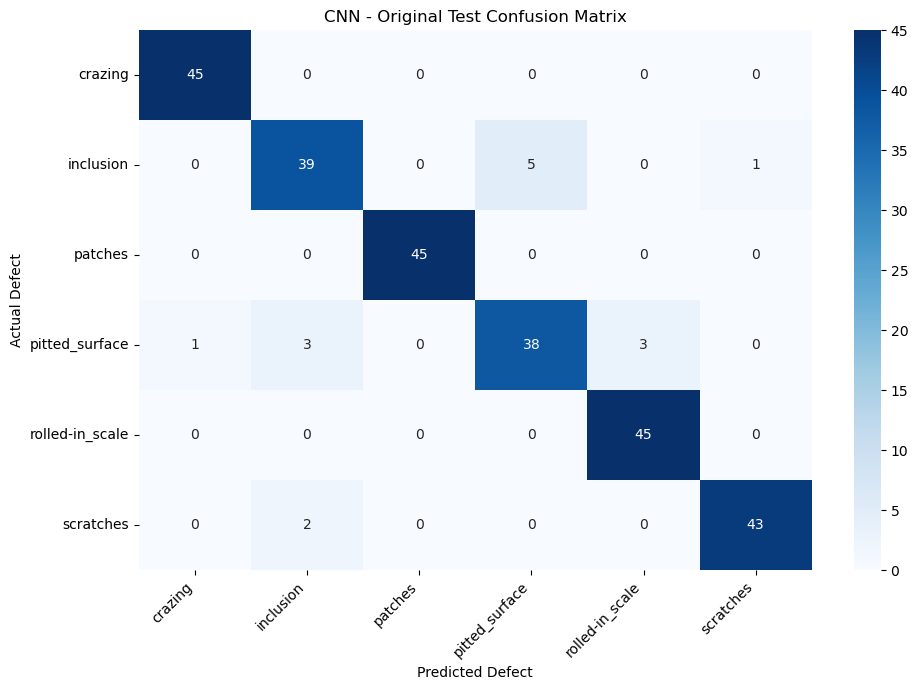

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test_original,
    y_pred_original,
    labels=range(len(cate))
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cate,
    yticklabels=cate
)

plt.xlabel("Predicted Defect")
plt.ylabel("Actual Defect")
plt.title("CNN - Original Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [31]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Image size
image_size = 128

# Load VGG16 base model
base_model = VGG16(
    include_top=False,
    weights='imagenet',
    input_shape=(image_size, image_size, 3)
)

# Freeze pretrained layers
for layer in base_model.layers:
    layer.trainable = False

# Build model
model_vgg16 = Sequential()

model_vgg16.add(base_model)
model_vgg16.add(Flatten())
model_vgg16.add(Dense(128, activation='relu'))
model_vgg16.add(Dropout(0.5))
model_vgg16.add(Dense(6, activation='softmax'))

# Compile model
model_vgg16.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
X_train = preprocess_input(X_train) #  cnvert the open cv images in the format that was used in VGG16
X_test  = preprocess_input(X_test)


TypeError: unsupported operand type(s) for -: 'float' and 'tuple'

In [32]:
from tensorflow.keras.applications.vgg16 import preprocess_input

# Use the normalized RGB arrays prepared earlier
X_train_vgg = preprocess_input(X_train_normalized * 255.0)
X_valid_vgg = preprocess_input(X_valid_normalized * 255.0)

history_vgg16 = model_vgg16.fit(
    X_train_vgg,
    y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_valid_vgg, y_valid),
    verbose=1
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 127s 419ms/step - accuracy: 0.9229 - loss: 0.4242 - val_accuracy: 0.9815 - val_loss: 0.0509
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 132s 439ms/step - accuracy: 0.9685 - loss: 0.1230 - val_accuracy: 0.9815 - val_loss: 0.1715
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 130s 434ms/step - accuracy: 0.9796 - loss: 0.1034 - val_accuracy: 0.9778 - val_loss: 0.1690
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 131s 436ms/step - accuracy: 0.9825 - loss: 0.0707 - val_accuracy: 0.9852 - val_loss: 0.0848
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 620s 2s/step - accuracy: 0.9783 - loss: 0.1294 - val_accuracy: 0.9815 - val_loss: 0.1265


In [33]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Predict classes for the original test images
y_pred_prob = model_vgg16.predict(X_test_vgg)
y_pred = np.argmax(y_pred_prob, axis=1)

# Test accuracy
test_accuracy = accuracy_score(y_test_original, y_pred)

print("VGG16 Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Detailed performance report
print(classification_report(
    y_test_original,
    y_pred,
    target_names=cate
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step
VGG16 Test Accuracy: 97.41 %
                 precision    recall  f1-score   support

        crazing       1.00      0.98      0.99        45
      inclusion       0.91      0.96      0.93        45
        patches       0.98      1.00      0.99        45
 pitted_surface       0.95      0.91      0.93        45
rolled-in_scale       1.00      1.00      1.00        45
      scratches       1.00      1.00      1.00        45

       accuracy                           0.97       270
      macro avg       0.97      0.97      0.97       270
   weighted avg       0.97      0.97      0.97       270



In [25]:
print("X_train minimum:", X_train.min())
print("X_train maximum:", X_train.max())
print("X_train shape:", X_train.shape)

X_train minimum: -123.68
X_train maximum: -102.939
X_train shape: (4800, 128, 128, 3)


In [26]:
print("X_train range:", X_train.min(), X_train.max())
print("X_test_original range:",
      X_test_original.min(), X_test_original.max())

X_train range: -123.68 -102.939
X_test_original range: 0.0 1.0


In [27]:
print("input_image exists:", 'input_image' in globals())
print("X_train exists:", 'X_train' in globals())

input_image exists: True
X_train exists: True


In [28]:
import numpy as np

# Restore original images from the training list
X_train_normalized = np.array(
    [item[0] for item in train],
    dtype="float32"
) / 255.0

y_train = np.array([item[1] for item in train])

# Convert OpenCV BGR images to RGB
X_train_normalized = X_train_normalized[..., ::-1]

print("Minimum:", X_train_normalized.min())
print("Maximum:", X_train_normalized.max())
print("Shape:", X_train_normalized.shape)
print("Labels shape:", y_train.shape)

Minimum: 0.0
Maximum: 1.0
Shape: (4800, 128, 128, 3)
Labels shape: (4800,)


In [29]:
from tensorflow.keras.applications.vgg16 import preprocess_input

# Preprocess training images
X_train_vgg = preprocess_input(
    X_train_normalized * 255.0
)

# Preprocess original test images
X_test_vgg = preprocess_input(
    X_test_original * 255.0
)

print("Training shape:", X_train_vgg.shape)
print("Testing shape:", X_test_vgg.shape)

print("Training range:",
      X_train_vgg.min(), X_train_vgg.max())

print("Testing range:",
      X_test_vgg.min(), X_test_vgg.max())

Training shape: (4800, 128, 128, 3)
Testing shape: (270, 128, 128, 3)
Training range: -123.68 151.061
Testing range: -123.68 151.061


In [30]:
import os
import cv2
import numpy as np

dataset_path = r"C:\Users\arjun\Downloads\Steel_Defect_Dataset_Final"

cate = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

X_valid_normalized = []
y_valid = []

valid_path = os.path.join(dataset_path, "valid")

for label, category in enumerate(cate):
    folder = os.path.join(valid_path, category)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)
        image = cv2.imread(image_path)

        if image is not None:
            image = cv2.resize(image, (128, 128))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            X_valid_normalized.append(image)
            y_valid.append(label)

X_valid_normalized = (
    np.array(X_valid_normalized, dtype="float32") / 255.0
)
y_valid = np.array(y_valid)

X_valid_vgg = preprocess_input(
    X_valid_normalized * 255.0
)

print("Validation images:", X_valid_vgg.shape)
print("Validation labels:", y_valid.shape)

Validation images: (270, 128, 128, 3)
Validation labels: (270,)


In [35]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load pretrained ResNet50
base_model_resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze pretrained layers
base_model_resnet.trainable = False

# Build six-class classification model
model_resnet50 = Sequential([
    tf.keras.Input(shape=(128, 128, 3)),
    base_model_resnet,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(6, activation="softmax")
])

model_resnet50.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

X_train_resnet = preprocess_input(
    X_train_normalized * 255.0
)

X_valid_resnet = preprocess_input(
    X_valid_normalized * 255.0
)

X_test_resnet = preprocess_input(
    X_test_original * 255.0
)
history_resnet = model_resnet50.fit(
    X_train_resnet,
    y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_valid_resnet, y_valid),
    verbose=1
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 267s 836ms/step - accuracy: 0.9552 - loss: 0.1389 - val_accuracy: 0.9926 - val_loss: 0.0311
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 244s 812ms/step - accuracy: 0.9935 - loss: 0.0241 - val_accuracy: 0.9889 - val_loss: 0.0351
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 243s 810ms/step - accuracy: 0.9962 - loss: 0.0125 - val_accuracy: 0.9926 - val_loss: 0.0423
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 250s 834ms/step - accuracy: 0.9958 - loss: 0.0105 - val_accuracy: 0.9926 - val_loss: 0.0366
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 316s 1s/step - accuracy: 0.9919 - loss: 0.0226 - val_accuracy: 0.9852 - val_loss: 0.0599


In [36]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_resnet_prob = model_resnet50.predict(X_test_resnet)
y_pred_resnet = np.argmax(y_pred_resnet_prob, axis=1)

resnet_accuracy = accuracy_score(
    y_test_original,
    y_pred_resnet
)

print("ResNet50 Test Accuracy:",
      round(resnet_accuracy * 100, 2), "%")

print(classification_report(
    y_test_original,
    y_pred_resnet,
    target_names=cate
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step
ResNet50 Test Accuracy: 99.63 %
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        45
      inclusion       0.98      1.00      0.99        45
        patches       1.00      1.00      1.00        45
 pitted_surface       1.00      0.98      0.99        45
rolled-in_scale       1.00      1.00      1.00        45
      scratches       1.00      1.00      1.00        45

       accuracy                           1.00       270
      macro avg       1.00      1.00      1.00       270
   weighted avg       1.00      1.00      1.00       270



In [37]:
from sklearn.metrics import accuracy_score
import numpy as np

correct = np.sum(y_test_original == y_pred_resnet)
total = len(y_test_original)

print("Correct predictions:", correct)
print("Total test images:", total)
print("Exact test accuracy:",
      round(accuracy_score(y_test_original, y_pred_resnet) * 100, 4), "%")

Correct predictions: 269
Total test images: 270
Exact test accuracy: 99.6296 %


In [42]:
model_resnet50.save(
    r"C:\Users\arjun\Downloads\resnet50_industrial_defect.keras"
)

print("ResNet50 model saved successfully!")

ResNet50 model saved successfully!


In [43]:
model_resnet50.save(
    r"C:\Users\arjun\Downloads\resnet50_industrial_defect.keras"
)